# AP 155 Lab Exercise
---
## Exercise 13: Ordinary differential equations

_Instructions_: 
- **Report Figure:** Generate two figures: (1) famous Lorenz butterfly $x-z$ plot and (2) Van-der-Pol oscillator phase space plot
- **Report Discussion:** Explain the dynamics in the figures. Discuss how both Euler's method and Runge-Kutta method work in a nutshell. Distinguish the advantages and disadvantages between Euler vs RK4.
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Baculo, Ezira Lojelle C.
- _Student No._: 2024-11845
- _Section_: THR-TX-3

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

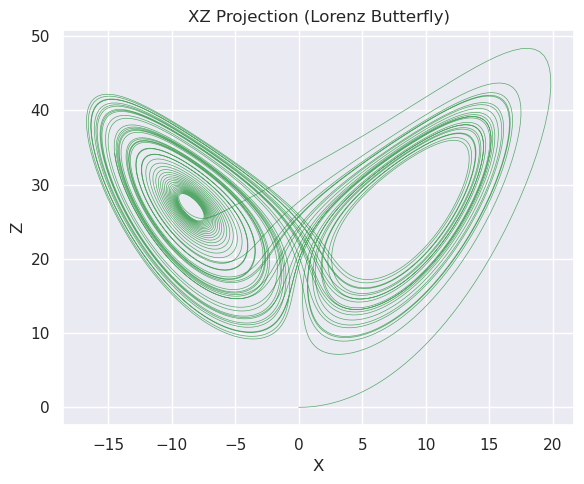

In [40]:
fig1

**Figure 1.** Lorenz strange attractor ($x-z$ projection). The trajectory creates the characteristic two-lobed butterfly-shaped attractor. The path constantly loops around the two lobes without repeating exactly.


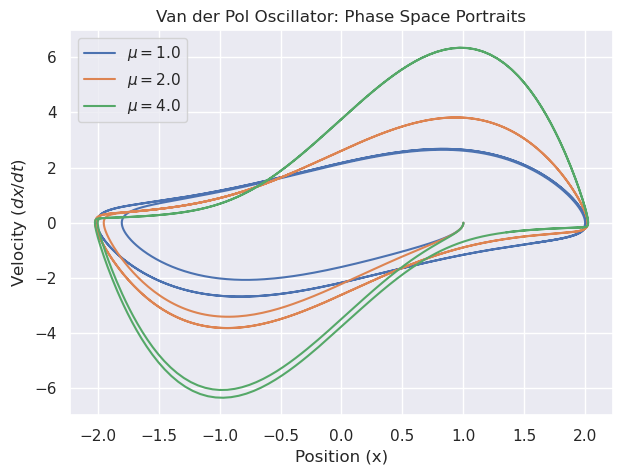

In [47]:
fig2

**Figure 2.** Van der Pol oscillator phase space. The curves show velocity against position for $\mu=1$, $2$, and $4$. Each trajectory converges to a closed limit cycle. The cycle increasingly resembles relaxation as $\mu$ increases.


### Report discussion

*(1) Explain the dynamics in the figures.*
- The Lorenz system exhibits deterministic chaos. The system revolves around two unstable fixed points (the butterfly's wings), and the path moves unpredictably between these regions of attraction without ever crossing itself. Its behavior are highly sensitive to initial conditions. On the other hand, the van der Pol oscillator is a self-oscillating non-linear system. Due to its non-linear damping term $\mu(1-x^2)\dot{x}$, the system receives energy when $|x| < 1$ and loses energy when $|x| > 1$. This drives all non-zero trajectories toward a distinct, stable isolated closed orbit in phase space known as a stable limit cycle. Higher values of $\mu$ sharpen the relaxation oscillations, changing the geometry of the cycle.

*(2) Discuss how both Euler's method and Runge-Kutta method work in a nutshell.*
- Euler's method is a first-order numerical method that estimates the next state by projecting a straight line along the local derivative at the current point: $y_{n+1} = y_n + h f(t_n, y_n)$. In contrast, the 4th-order Runge-Kutta (RK4) method evaluates four tentative derivative steps across the interval: one at the beginning ($k_0$), two at the midpoint ($k_1, k_2$), and one at the end ($k_3$). Calculating a weighted average of these estimates canceled out lower-order error terms, resulting in an accurate step consistent with the Taylor expansion up to fourth order.

*(3) Distinguish the advantages and disadvantages between Euler vs RK4.*
| Method | Advantages | Disadvantages |
| :--- | :--- | :--- |
| **Euler's Method** | Simple to write, understand, and computationally cheap per step. | Highly unstable; the local truncation error is $\mathcal{O}(h^2)$ and global error is $\mathcal{O}(h)$. It accumulates error quickly (e.g., causing artificial energy increase in the simple pendulum) and needs extremely small step sizes $h$. |
| **RK4 Method** | Highly stable and accurate, with a global error of $\mathcal{O}(h^4)$. It can solve complex chaotic and non-linear paths with comparatively large step sizes. | Needs four function evaluations per step, making it computationally expensive per step and more complex to implement. |


### Other comments
- Oki naman po hehehe. Konting push na lang at matatapos na rin ang sem. FINALLY!
- Excited na po ako para sa Christmas break.
- 🎄🎄🎄

#### Disclosure of AI Use:

I acknowledge the use of Gemini (accessed November 2026) to generate a first draft of the algorithms. All AI-assisted suggestions were reviewed and revised with the help of the references provided in the lecture and researched to ensure accuracy and clarity of meaning.

---
## Section 2: Code

In [2]:
import matplotlib.pyplot as plt
import numpy as np

import seaborn as sns # Guide: https://seaborn.pydata.org/tutorial/introduction.html
sns.set_theme(style="darkgrid")

rng = np.random.default_rng()

### Practice: Simple pendulum
$$\frac{d^2\theta}{dt^2}=-\frac{g}{l}\sin\theta $$

- Variables: ${\theta}$
- Parameters: ${g, l}$

To solve a second-order ODE, we reduce it to two first-order ODEs.
Let $\theta = y_0$ and $\omega = \frac{d\theta}{dt} = y_1$.
The system becomes:
\begin{align}
\frac{d \theta}{dt} &= \omega \\
\frac{d \omega}{dt} &= -\frac{g}{l}\sin(\theta)
\end{align}

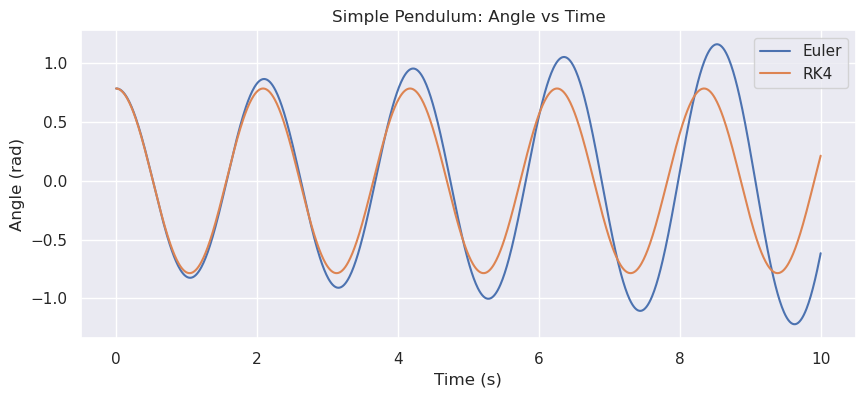

In [48]:
# practice mode

# global constants
g = 9.81
l = 1.0
    
def pendulum_ode(t, state):
    theta, omega = state
    return np.array([omega, -(g / l) * np.sin(theta)])

# Define eulergen and rk4gen
def eulergen(f, a, b, n, yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, len(yinit)))
    y = np.array(yinit, dtype=float)
    for j, x in enumerate(xs):
        ys[j, :]
        ys[j, :] = y
        y += h*f(x, y)
    return xs, ys

def rk4gen(fs, a, b, n, yinits):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, yinits.size))
    yvals = np.copy(yinits)
    for j, x in enumerate(xs):
        ys[j, :]
        ys[j, :] = yvals
        k0 = h*fs(x, yvals)
        k1 = h*fs(x+h/2, yvals+k0/2)
        k2 = h*fs(x+h/2, yvals+k1/2)
        k3 = h*fs(x+h, yvals+k2)
        yvals += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys

# given time interval from 0 to 10 seconds sampled at 1000 pts, define a, b, n
a, b, n = 0.0, 10.0, 1000

# init conds (arbitrary): pi/4 angle, 0 initial velocity
yinit = np.array([np.pi / 4, 0.0]) # theta0, omega0

t, Y_euler = eulergen(pendulum_ode, a, b, n, yinit)
t, Y_rk4 = rk4gen(pendulum_ode, a, b, n, yinit)

plt.figure(figsize=(10,4))
plt.plot(t, Y_euler[:,0], label='Euler')
plt.plot(t, Y_rk4[:,0], label='RK4')
plt.title("Simple Pendulum: Angle vs Time")
plt.xlabel("Time (s)")
plt.ylabel("Angle (rad)")
plt.legend()
plt.show()

### Exercise 1: Simultaneous 1st order ODEs

One of the most celebrated sets of differential equations in physics is the Lorenz equations
\begin{align}
\frac{dx}{dt} &= \sigma(y-x) \\
\frac{dy}{dt} &= \rho x - y - xz\\
\frac{dz}{dt} &= xy - \beta z \\
\end{align}
where $\mu$, $\rho$, and $\beta$ are constants. (The names $\mu$, $\rho$, and $\beta$ are odd, but traditional --- they
are always used in these equations for historical reasons.)

These equations were first studied by Edward Lorenz in 1963, who derived them from a simplified model of weather patterns. The reason for their fame is that they were one of the first incontrovertible examples of *deterministic chaos*, the occurrence of apparently random motion even though there is no randomness built into the equations. We encountered a different example of chaos in the logistic map.

**(a)** Write a program to solve the Lorenz equations for the case $\sigma = 10$, $\rho = 28$, and $\beta =\frac{8}{3}$ in the range from $t = 0$ to $t = 50$ with initial conditions $(x,y,z) =(0, 1,0)$. Plot the trajectory $(x(t), y(t), z(t))$ for different parameter values. One trajectory should clearly illustrate the chaotic behavior of the Lorenz attractor.

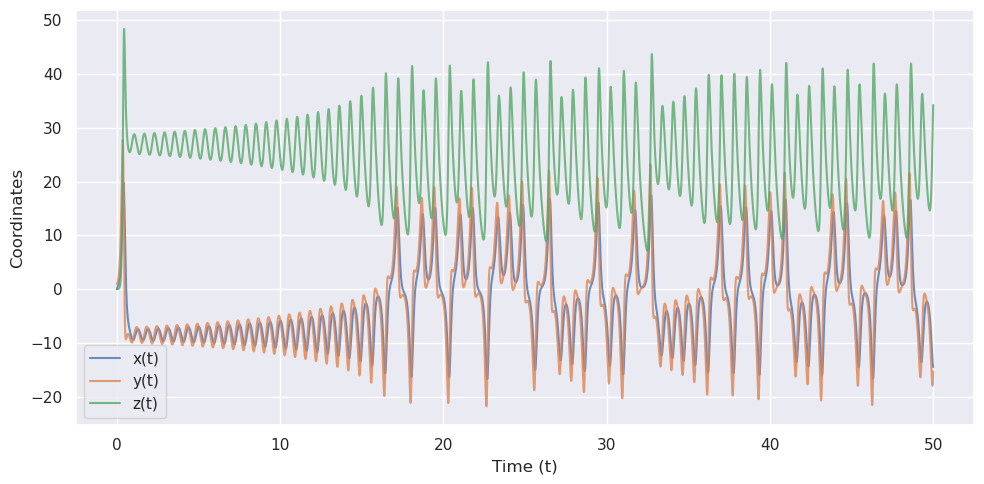

In [51]:
sigma = 10.0
rho = 28.0
beta = 8/3

def lorenz_ode(t, state):
    x, y, z = state
    dxdt = sigma * (y - x)
    dydt = rho * x - y - x * z
    dzdt = x * y - beta * z
    return np.array([dxdt, dydt, dzdt])

# Solver settings
a = 0.0
b = 50.0
n = 10000
yinit = np.array([0.0, 1.0, 0.0])

# Integrate using the previously defined rk4gen solver
t_pts, states = rk4gen(lorenz_ode, a, b, n, yinit)
x_pts, y_pts, z_pts = states[:, 0], states[:, 1], states[:, 2]

# Plot the time series for each coordinate to observe chaotic dynamics
plt.figure(figsize=(10, 5))
plt.plot(t_pts, x_pts, label='x(t)', alpha=0.8)
plt.plot(t_pts, y_pts, label='y(t)', alpha=0.8)
plt.plot(t_pts, z_pts, label='z(t)', alpha=0.8)
plt.xlabel("Time (t)")
plt.ylabel("Coordinates")
plt.legend()
plt.tight_layout()
plt.show()

**(b)** Modify your program to produce a plot of $z$ against $x$. You should see a picture of the famous "strange attractor" of the Lorenz equations, a lop-sided butterfly-shaped plot that never repeats itself.

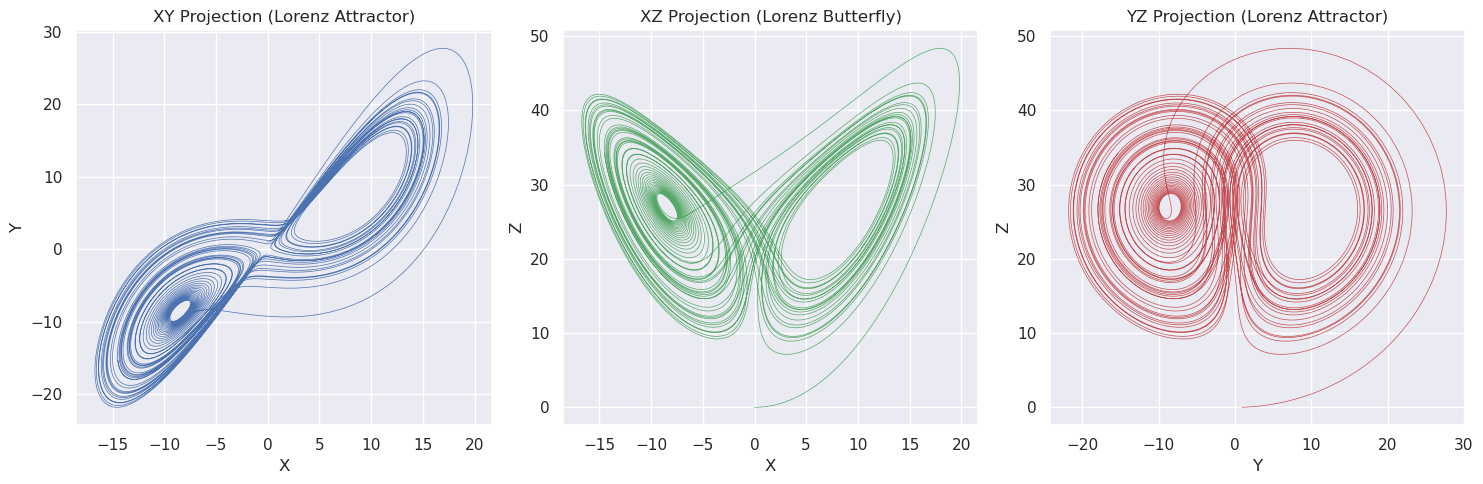

In [52]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

# XY-Plane Projection
axs[0].plot(x_pts, y_pts, color='b', lw=0.5)
axs[0].set_title("XY Projection (Lorenz Attractor)")
axs[0].set_xlabel("X")
axs[0].set_ylabel("Y")

# XZ-Plane Projection (lopsided butterfly)
axs[1].plot(x_pts, z_pts, color='g', lw=0.5)
axs[1].set_title("XZ Projection (Lorenz Butterfly)")
axs[1].set_xlabel("X")
axs[1].set_ylabel("Z")

# YZ-Plane Projection
axs[2].plot(y_pts, z_pts, color='r', lw=0.5)
axs[2].set_title("YZ Projection (Lorenz Attractor)")
axs[2].set_xlabel("Y")
axs[2].set_ylabel("Z")

plt.tight_layout()
plt.show()

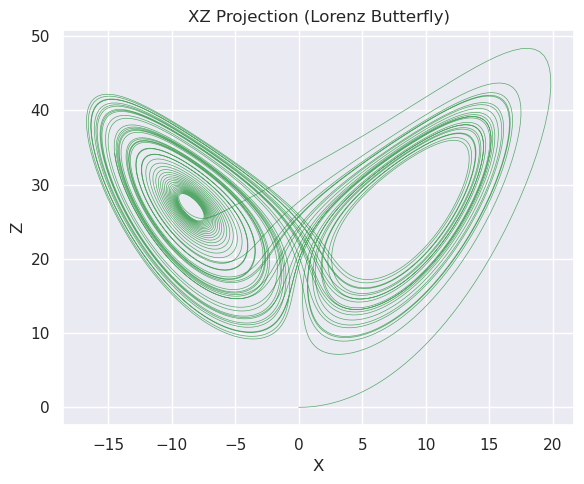

In [53]:
# fig1: Just the Lorenz butterfly (XZ-Plane Projection)
fig1, ax1 = plt.subplots(figsize=(6, 5))
ax1.plot(x_pts, z_pts, color="g", lw=0.5)
ax1.set_title("XZ Projection (Lorenz Butterfly)")
ax1.set_xlabel("X")
ax1.set_ylabel("Z")
fig1.tight_layout()

plt.show()

#### Problem 1 code summary

This script solves the three interconnected first-order Lorenz equations using a generalized 4th-order Runge-Kutta method (`rk4gen`). This method was chosen because RK4 provides fourth-order local accuracy, which is crucial for stably addressing the sensitive dependence on initial conditions characteristic of chaotic systems without requiring an unnecessarily small step size. The resulting paths were then projected onto 2D phase planes to illustrate the shape of the chaotic strange attractor.


### Exercise 2: Second-order ODEs (Harmonic and anharmonic oscillators)

The simple harmonic oscillator arises in many physical problems, in mechanics, electricity and magnetism, and condensed matter physics, among other areas. Consider the standard oscillator equation
$$ \frac{d^2x}{dt^2} = - \omega^2 x $$.

**(a)** Turn this second-order equation into two coupled first-order equations. Then write a program to solve them for the case $\omega = 1$ in the range from $t=0$ to $t= 50$. A second-order equation requires two initial conditions, one on $x$ and one on its derivative. For this problem use $x = 1$ and $\frac{dx}{dt} = 0$ as initial conditions. Have your program
make a graph showing the value of $x$ as a function of time.

$$ \frac{dx}{dt} = y$$
$$ \frac{dy}{dt} = - \omega^2 x $$

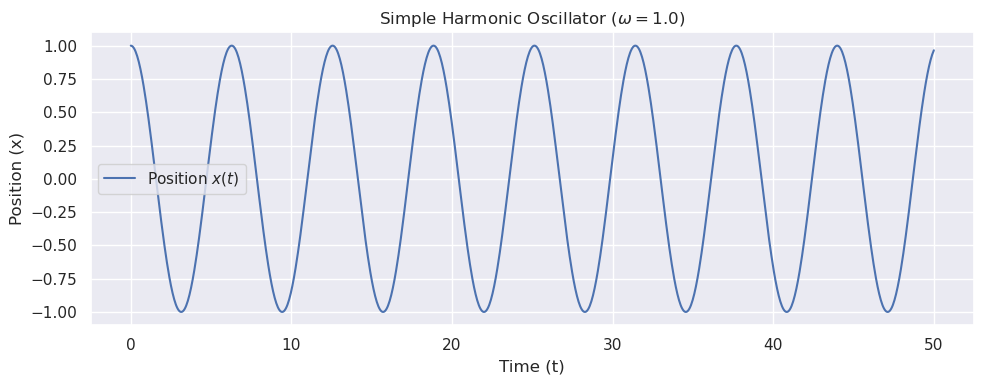

In [54]:
omega = 1.0

def sho_ode(t, state):
    x, y = state
    dxdt = y
    dydt = -(omega**2) * x
    return np.array([dxdt, dydt])

# Integration parameters
a_sho = 0.0
b_sho = 50.0
n_sho = 1000
yinit_sho = np.array([1.0, 0.0])

# Solve using rk4gen
t_sho, states_sho = rk4gen(sho_ode, a_sho, b_sho, n_sho, yinit_sho)
x_sho = states_sho[:, 0]

# Plot x as a function of time
plt.figure(figsize=(10, 4))
plt.plot(t_sho, x_sho, color='b', label='Position $x(t)$')
plt.title("Simple Harmonic Oscillator ($\omega = 1.0$)")
plt.xlabel("Time (t)")
plt.ylabel("Position (x)")
plt.legend()
plt.tight_layout()
plt.show()

**(b)** Now increase the amplitude of the oscillations by making the initial value of $x$ bigger --- say $x = 2$ --- and confirm that the period of the oscillations stays roughly the same.

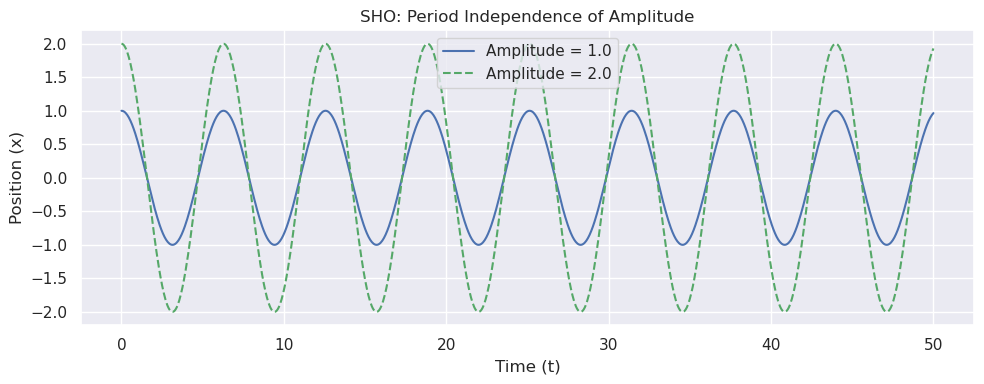

In [55]:
yinit_sho_large = np.array([2.0, 0.0])

# Solve using rk4gen
t_sho, states_sho_large = rk4gen(sho_ode, a_sho, b_sho, n_sho, yinit_sho_large)
x_sho_large = states_sho_large[:, 0]

# Plot both to show the period is the same
plt.figure(figsize=(10, 4))
plt.plot(t_sho, x_sho, 'b-', label='Amplitude = 1.0')
plt.plot(t_sho, x_sho_large, 'g--', label='Amplitude = 2.0')
plt.title("SHO: Period Independence of Amplitude")
plt.xlabel("Time (t)")
plt.ylabel("Position (x)")
plt.legend()
plt.tight_layout()
plt.show()

**(c)** Modify your program to solve for the motion of the anharmonic oscillator described by the equation
$$ \frac{d^2 x}{dt} = -\omega^2 x^3.$$

Again take $\omega= 1$ and initial conditions $x = 1$ and $dx/dt = 0$ and make a plot of the motion of the oscillator. Again increase the amplitude. You should observe that the oscillator oscillates faster at higher amplitudes. (You can try lower amplitudes too if you like, which should be slower.)

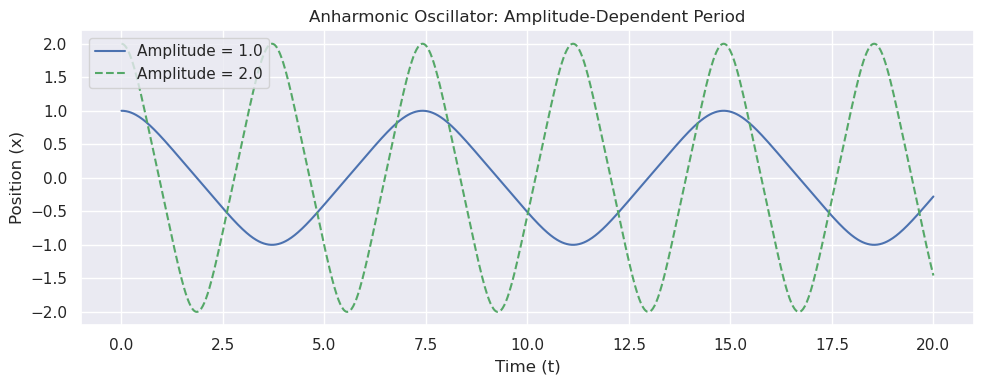

In [56]:
omega = 1.0

def anharmonic_ode(t, state):
    x, y = state
    dxdt = y
    dydt = -(omega**2) * (x**3)
    return np.array([dxdt, dydt])

# SImulation parameters
a_anh = 0.0
b_anh = 20.0
n_anh =  1000

# SOlve for amplitude = 1.0
yinit_anh1 = np.array([1.0, 0.0])
t_anh, states_anh1 = rk4gen(anharmonic_ode, a_anh, b_anh, n_anh, yinit_anh1)
x_anh1 = states_anh1[:, 0]

# Solve for larger amplitude = 2.0
yinit_anh2 = np.array([2.0, 0.0])
t_anh, states_anh2 = rk4gen(anharmonic_ode, a_anh, b_anh, n_anh, yinit_anh2)
x_anh2 = states_anh2[:, 0]

# Plot the comparative motions
plt.figure(figsize=(10, 4))
plt.plot(t_anh, x_anh1, 'b-', label='Amplitude = 1.0')
plt.plot(t_anh, x_anh2, 'g--', label='Amplitude = 2.0')
plt.title("Anharmonic Oscillator: Amplitude-Dependent Period")
plt.xlabel("Time (t)")
plt.ylabel("Position (x)")
plt.legend()
plt.tight_layout()
plt.show()

**(d)** Modify your program so that instead of plotting $x$ against $t$, it plots $\frac{dx}{dt}$ against $x$, i.e., the "velocity" of the oscillator against its "position." Such a plot is called a *phase space* plot.

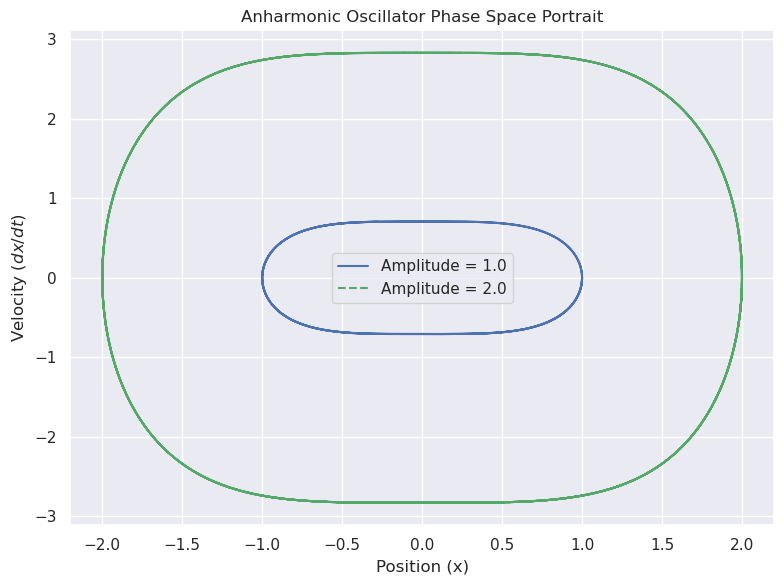

In [57]:
# Plotting velocity (dx/dt) against position (x)

"""
We extract the positions and velocities from our previous simulation states.
state[:, 0] is position (x), state[:, 1] is velocity (dx/dt)
"""
v_anh1 = states_anh1[:, 1]
v_anh2 = states_anh2[:, 1]

plt.figure(figsize=(8, 6))
plt.plot(x_anh1, v_anh1, 'b-', label='Amplitude = 1.0')
plt.plot(x_anh2, v_anh2, 'g--', label='Amplitude = 2.0')
plt.title("Anharmonic Oscillator Phase Space Portrait")
plt.xlabel("Position (x)")
plt.ylabel("Velocity ($dx/dt$)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

**(e)** The van der Pol oscillator, which appears in electronic circuits and in laser physics, is described by the equation
$$\frac{d^2x }{dt^2} - \mu(1-x^2)\frac{dx}{dt} + x = 0 $$
Use the same techniques as the one above (i.e. rewrite into 2 1st-order ODEs). Modify your program to solve this equation from $t=0$ to $t=20$ and hence make a phase space plot for the van der Pol oscillator with $\omega=1$, $\mu = 1$, and initial conditions $x = 1$ and $dx/dt = 0$. Try it also for $\mu=2$ and $\mu=4$ (still with $\omega = 1$). Make sure you use a small enough value of the time interval $h$ to get a smooth, accurate phase space plot.

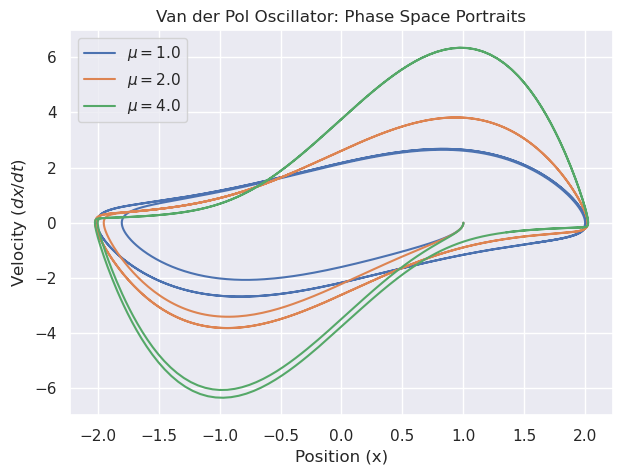

In [58]:
def vanderpol_ode(t, state, mu):
    x, y = state
    dxdt = y
    dydt = mu * (1.0 - x**2) * y - x
    return np.array([dxdt, dydt])

# Simulation parameters
a_vdp = 0.0
b_vdp = 20.0
n_vdp = 2000  # Large enough n to ensure smooth trajectories
yinit_vdp = np.array([1.0, 0.0])

fig2, ax = plt.subplots(figsize=(7, 5))

# Run simulation and plot for each value of mu
for mu in [1.0, 2.0, 4.0]:
    # Using a lambda function to pass parameter mu to our ODE function
    t_vdp, states_vdp = rk4gen(lambda t, s: vanderpol_ode(t, s, mu), a_vdp, b_vdp, n_vdp, yinit_vdp)
    x_vdp = states_vdp[:, 0]
    v_vdp = states_vdp[:, 1]

    ax.plot(x_vdp, v_vdp, label=rf"$\mu = {mu}$", lw=1.5)

ax.set_title("Van der Pol Oscillator: Phase Space Portraits")
ax.set_xlabel("Position (x)")
ax.set_ylabel("Velocity ($dx/dt$)")
ax.legend()
ax.grid(True)
fig.tight_layout()
plt.show()

#### Problem 2 code summary

This script simulates linear and non-linear oscillators by transforming second-order equations into coupled first-order ODEs and solving them using a generalized 4th-order Runge-Kutta algorithm (`rk4gen`). This execution guarantees numerical stability and energy-conserving behavior for periodic trajectories, showcasing key physical effects such as amplitude-independent periods in harmonic systems, amplitude-dependent periods in anharmonic phases, and stable limit cycles in the Van der Pol phase space.


### (BONUS) Exercise 3: Leap-frog method

The simple harmonic oscillator arises in many physical problems, in mechanics, electricity and magnetism, and condensed matter physics, among other areas. Consider the standard oscillator equation
$$ \frac{d^2x}{dt^2} = - \omega^2 x $$.

---
## Section 3: Notes

In [37]:
# forward Euler's method

def euler(f,a,b,n,yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros(n)
    y = yinit
    for j,x in enumerate(xs):
        ys[j] = y
        y += h*f(x, y)
    return xs, ys

In [38]:
# 2nd order Runge-Kutta method

def rk2(f,a,b,n,yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros(n)
    y = yinit
    for j,x in enumerate(xs):
        ys[j] = y
        k1 = h*f(x, y)
        k2 = h*f(x+0.5*h, y+0.5*k1)
        y += k2
    return xs, ys

In [39]:
# 4th order Runge-Kutta method (1 equation only, use the code below for simultaneous eqns)

def rk4(f,a,b,n,yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros(n)
    y = yinit
    for j,x in enumerate(xs):
        ys[j] = y
        k0 = h*f(x, y)
        k1 = h*f(x+h/2, y+k0/2)
        k2 = h*f(x+h/2, y+k1/2)
        k3 = h*f(x+h, y+k2)
        y += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys

[19.53       19.59919146 19.67369182 19.75226242 19.83257721]
[19.53       19.60199388 19.6790241  19.75924981 19.83967675]
[19.53       19.60202244 19.67902463 19.75914998 19.83939363]


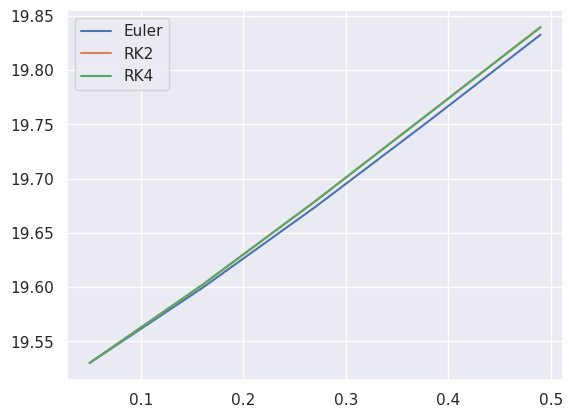

In [43]:
# execution
a, b, n, yinit = 0.05, 0.49, 5, 19.53

xs, ys = euler(f,a,b,n,yinit); print(ys)
plt.plot(xs,ys, label='Euler')
xs, ys = rk2(f,a,b,n,yinit); print(ys)
plt.plot(xs,ys, label='RK2')
xs, ys = rk4(f,a,b,n,yinit); print(ys)
plt.plot(xs,ys, label='RK4')
plt.legend()
plt.show()

#### Solving IVP problem of 2 simultaneous ODEs

In [46]:
def fs(x,yvals):
    y0, y1 = yvals
    f0 = y1
    f1 = - (30/(1-x**2))*y0 + ((2*x)/(1-x**2))*y1
    return np.array([f0, f1])
    
def rk4gen(fs,a,b,n,yinits):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, yinits.size))
    yvals = np.copy(yinits)
    for j,x in enumerate(xs):
        ys[j,:] = yvals
        k0 = h*fs(x, yvals)
        k1 = h*fs(x+h/2, yvals+k0/2)
        k2 = h*fs(x+h/2, yvals+k1/2)
        k3 = h*fs(x+h, yvals+k2)
        yvals += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys

a, b, n = 0.05, 0.49, 12
yinits = np.array([0.0926587109375, 1.80962109375])
xs, ys = rk4gen(fs,a,b,n,yinits)
print(ys)

[[ 0.09265871  1.80962109]
 [ 0.16241651  1.66496084]
 [ 0.22481633  1.44262901]
 [ 0.27687631  1.1492782 ]
 [ 0.3159291   0.79398005]
 [ 0.33971857  0.38822519]
 [ 0.34649662 -0.05407672]
 [ 0.33511993 -0.51659705]
 [ 0.3051467  -0.98058819]
 [ 0.25693343 -1.42488364]
 [ 0.19173167 -1.82589807]
 [ 0.1117848  -2.15762739]]


In [44]:
def eulergen(f, a, b, n, yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, len(yinit))) 
    y = np.array(yinit, dtype=float)
    for j, x in enumerate(xs):
        ys[j, :] = y
        y += h*f(x, y)
    return xs, ys

### Plotting

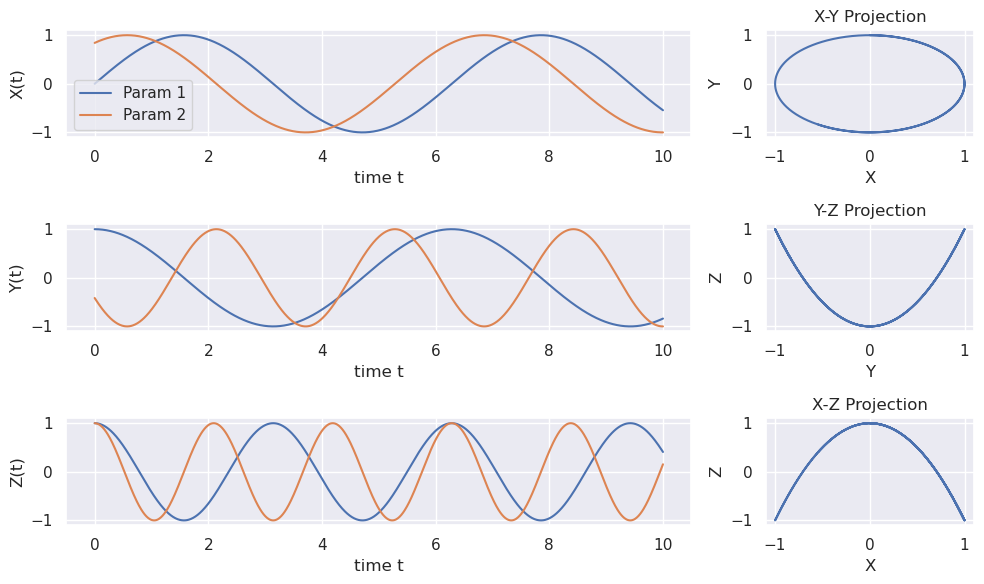

In [31]:
# SAMPLE DATA ONLY
t = np.linspace(0, 10, 1000)
x = np.sin(t)
y = np.cos(t)
z = np.cos(2*t)

x1 = np.sin(t + 1)
y1 = np.cos(2*t + 2)
z1 = np.cos(3*t)

# See: https://stackoverflow.com/questions/10388462/matplotlib-different-size-subplots
fig, axs = plt.subplots(3, 2, figsize=(10, 6), gridspec_kw={'width_ratios': [3, 1]})

# Time series
axs[0, 0].plot(t, x, label="Param 1")
axs[0, 0].plot(t, x1, label="Param 2")
axs[0, 0].legend()
axs[0, 0].set_ylabel("X(t)")

axs[1, 0].plot(t, y)
axs[1, 0].plot(t, y1)
axs[1, 0].set_ylabel("Y(t)")

axs[2, 0].plot(t, z)
axs[2, 0].plot(t, z1)
axs[2, 0].set_ylabel("Z(t)")

# add xlabel to all time series
for ax in axs[:, 0]:
    ax.set_xlabel("time t")

# Phase plot
axs[0, 1].plot(x, y)
axs[0, 1].set(title="X-Y Projection", xlabel="X", ylabel="Y")

axs[1, 1].plot(y, z)
axs[1, 1].set(title="Y-Z Projection", xlabel="Y", ylabel="Z")

axs[2, 1].plot(x, z)
axs[2, 1].set(title="X-Z Projection", xlabel="X", ylabel="Z")

fig.tight_layout()